In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


# Execrise 1.1

In [2]:
# Read data
df = pd.read_csv("/content/transactions.csv")

In [3]:
nulls = df.isnull().sum(axis=0).sort_values(ascending=False); nulls

,0
Unnamed: 0,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0


In [4]:
df

,Unnamed: 0,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.00,0.00,0
1,1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.00,0.00,0
2,2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.00,0.00,1
3,3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.00,0.00,1
4,4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.00,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...
199995,199995,13,CASH_IN,149024.27,C1446913085,8688.0,157712.27,C476402209,440028.59,321427.51,0
199996,199996,13,PAYMENT,71076.01,C1421983410,50291.0,0.00,M855368711,0.00,0.00,0
199997,199997,13,CASH_OUT,147125.05,C80624764,0.0,0.00,C747330421,1058502.64,1325544.47,0
199998,199998,13,CASH_OUT,97529.67,C595001108,0.0,0.00,C575555170,1921846.97,2019376.64,0


# Exercise 1.2

In [5]:
df.dropna().describe()

,Unnamed: 0,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
count,200000.000000,200000.00000,2.000000e+05,2.000000e+05,2.000000e+05,2.000000e+05,2.000000e+05,200000.000000
mean,99999.500000,10.06589,1.808112e+05,8.821957e+05,9.001938e+05,9.411592e+05,1.191866e+06,0.000735
std,57735.171256,2.12174,3.291800e+05,2.766264e+06,2.803759e+06,2.373010e+06,2.655236e+06,0.027101
min,0.000000,1.00000,3.200000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,49999.750000,9.00000,1.201612e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
50%,99999.500000,10.00000,6.872104e+04,1.951000e+04,0.000000e+00,5.055850e+04,1.320839e+05,0.000000
75%,149999.250000,12.00000,2.290791e+05,1.915686e+05,2.275212e+05,7.645361e+05,1.189164e+06,0.000000
max,199999.000000,13.00000,1.000000e+07,3.893942e+07,3.894623e+07,3.903958e+07,3.904248e+07,1.000000


# Exercise 1.3

,count
isFraud,
0,199853
1,147


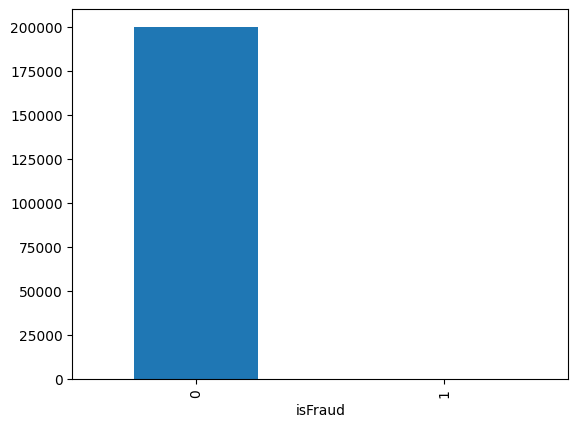

In [6]:
df['isFraud'].value_counts().plot(kind='bar')
df['isFraud'].value_counts()

In [7]:
print('Proportion of fraud trades: {:.2f}%'.format(df['isFraud'].value_counts()[1]/df['isFraud'].size * 100))

Proportion of fraud trades: 0.07%


# Exercise 1.4

<Axes: xlabel='isFraud'>

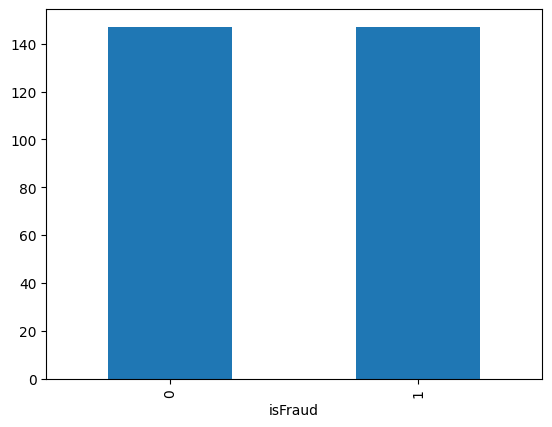

In [8]:
fraud_count = len(df[df['isFraud'] == 1])
non_fraud_count = len(df[df['isFraud'] == 0])

sampled_non_fraud = df[df['isFraud'] == 0].sample(n=fraud_count)
fraud = df[df['isFraud'] == 1]

sampled_non_fraud.reset_index(drop=True, inplace=True)
fraud.reset_index(drop=True, inplace=True)

balanced_df = pd.concat([sampled_non_fraud, fraud]).reset_index(drop=True);

balanced_df['isFraud'].value_counts().plot(kind='bar')

# Exercise 1.4

<Axes: title={'center': 'Correlation matrix of sub-sampled data'}>

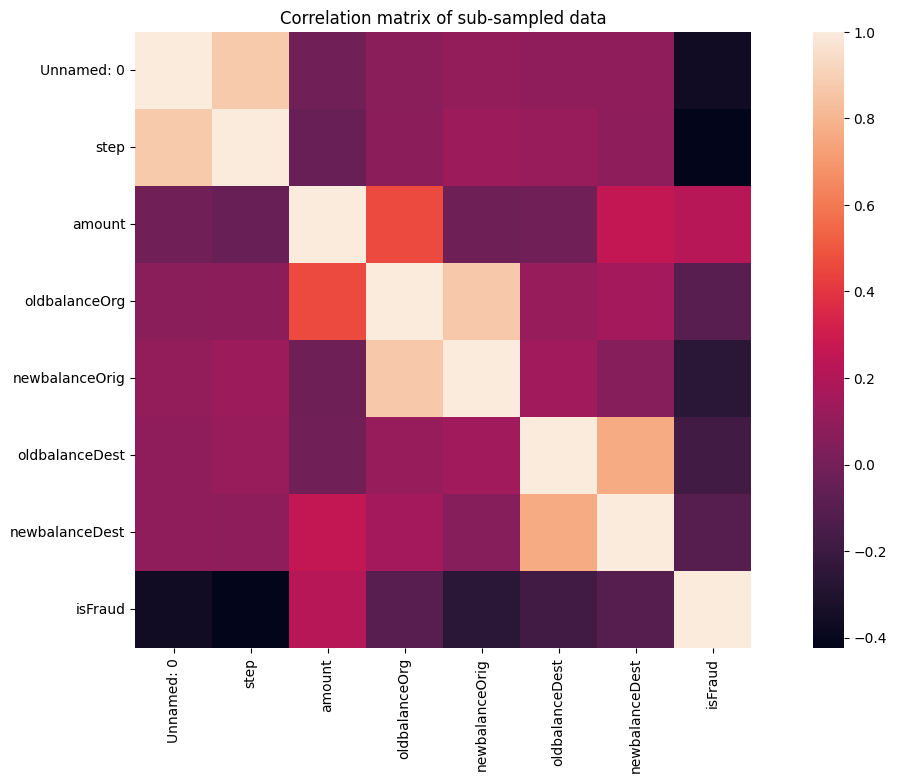

In [9]:
numeric_columns = balanced_df.select_dtypes(include=[np.number]).columns
corrmat = balanced_df[numeric_columns].corr()
f, ax = plt.subplots(figsize=(16, 8))
#plt.subplot(1, 2, 1)
plt.title('Correlation matrix of sub-sampled data')
sns.heatmap(corrmat, vmax=1, square=True)

# Exercise 1.5

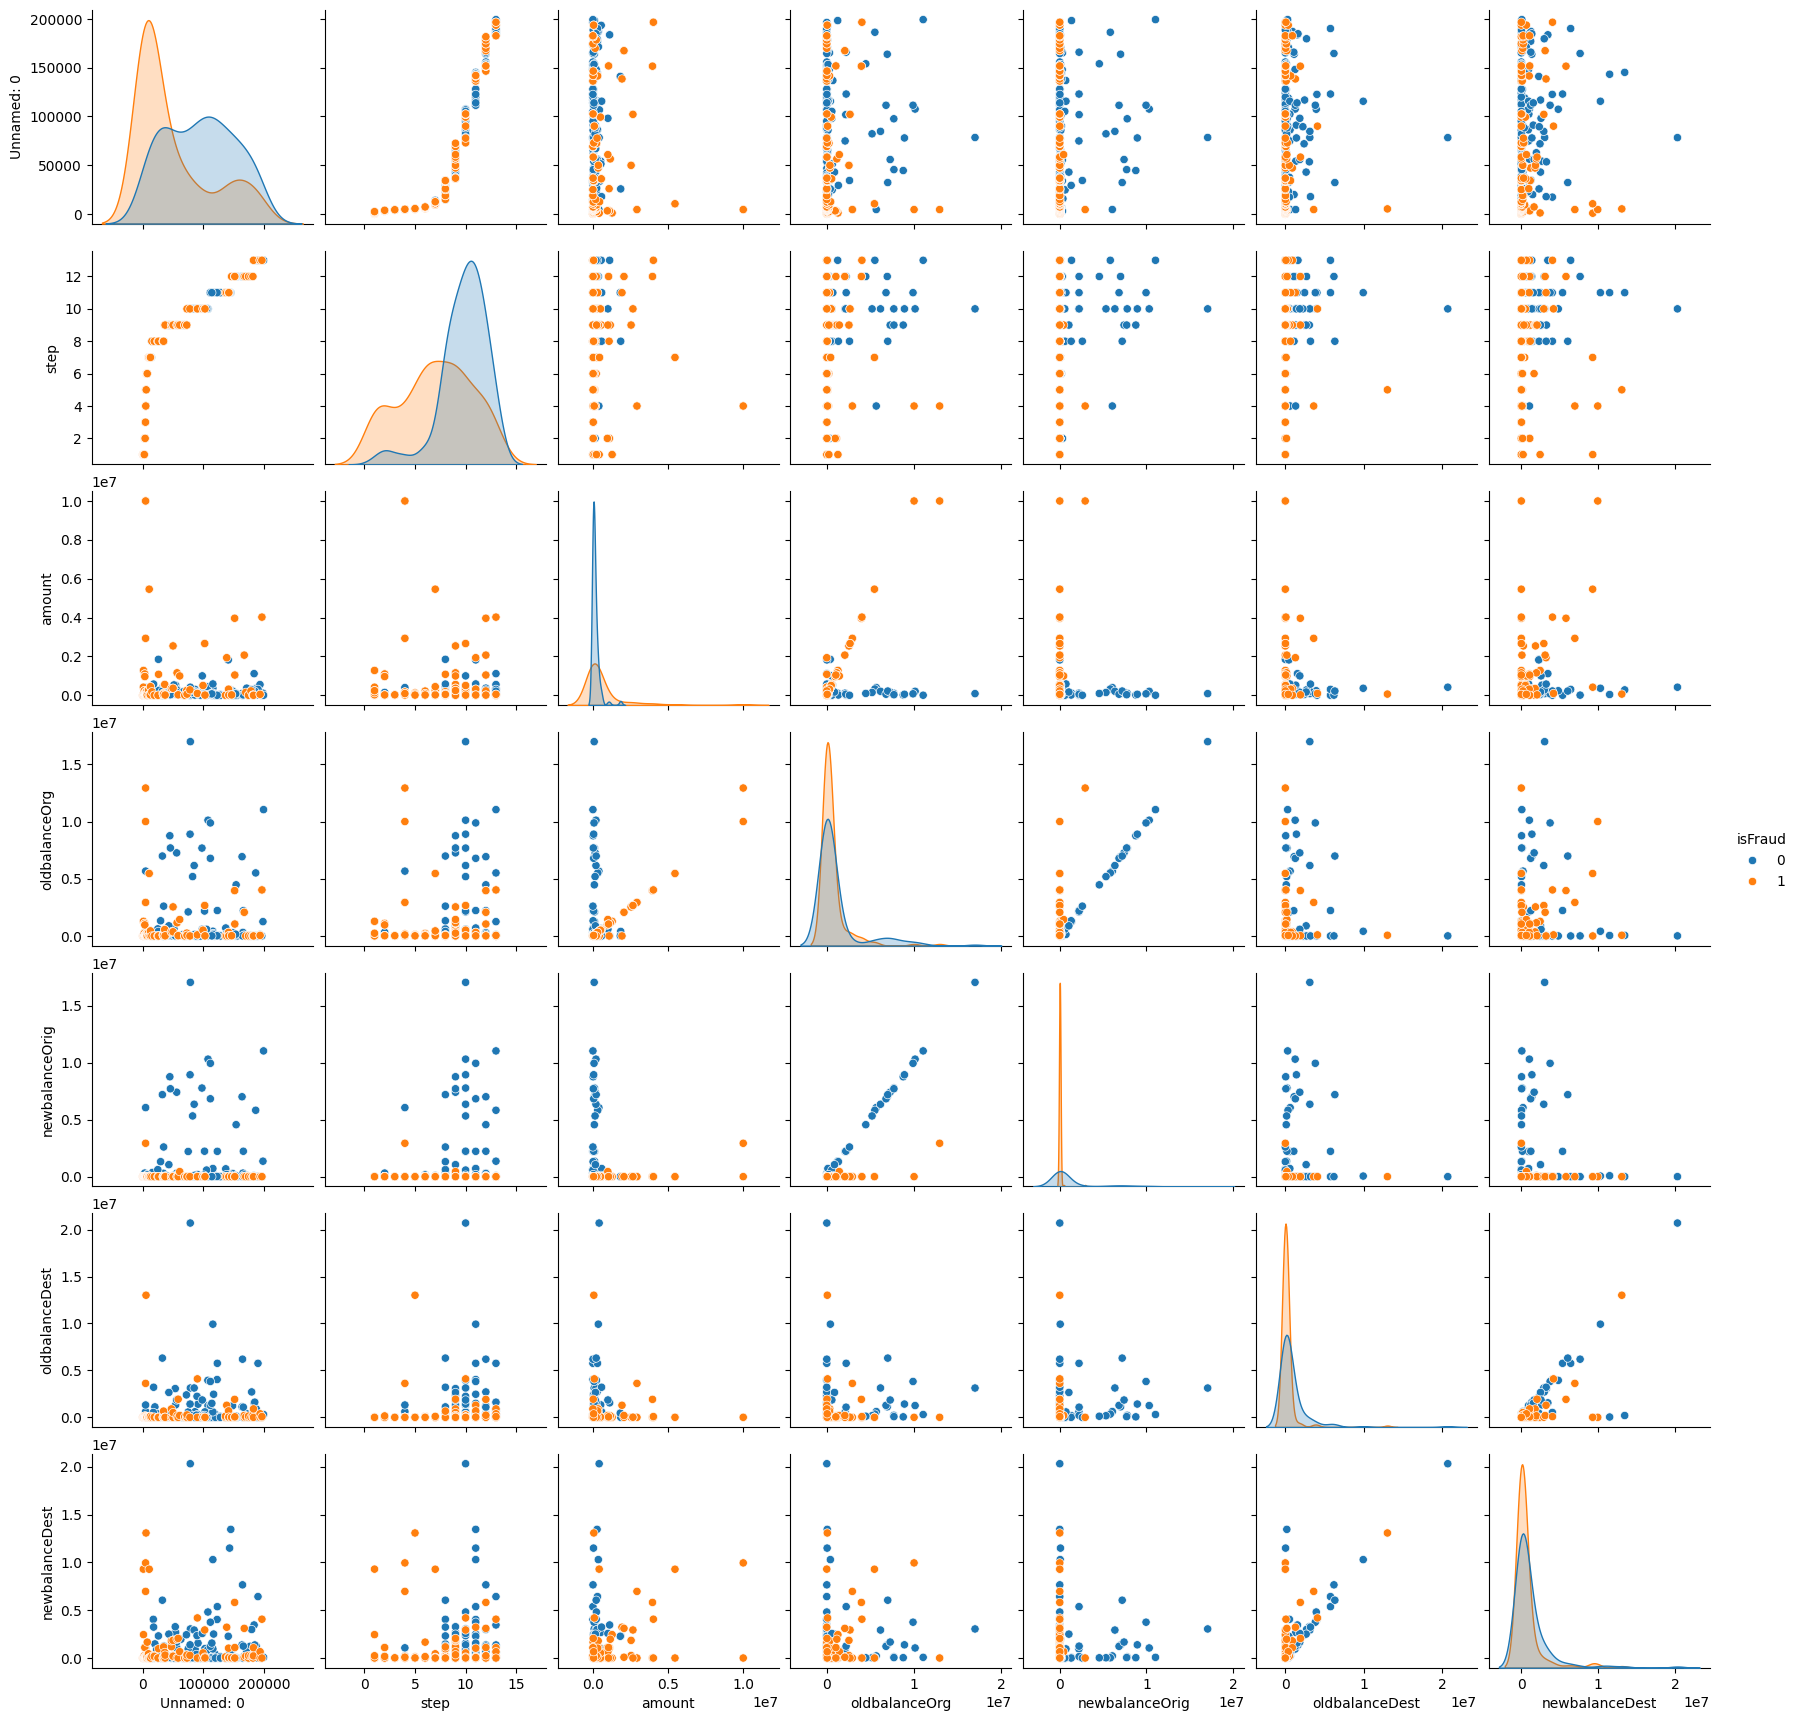

In [10]:
# creating the pair plots for all the fields of the dataset
sns.pairplot(balanced_df, hue='isFraud')

# Exercise 1.6

In [14]:
# Copy the balanced dataset
features = df.copy(deep=True)

In [15]:

# Add flag for whether the sender is a customer
features['clientType'] = features['nameOrig'].str.startswith('C').astype(int)

In [16]:
# Add flag for whether the receiver is a customer
features['clientBType'] = features['nameDest'].str.startswith('C').astype(int)

In [17]:
# Add binary flag for missing destination (not common in your case)
features['hasDest'] = ~features['nameDest'].isnull()
features['hasDest'] = features['hasDest'].astype(int)

In [18]:
# Drop columns that are IDs or duplicates
features = features.drop(columns=['nameOrig', 'nameDest', 'Unnamed: 0', 'isFraud'])

In [19]:
# Add delta columns as before
features['deltaOrig'] = df['oldbalanceOrg'] - df['newbalanceOrig']
features['deltaDest'] = df['newbalanceDest'] - df['oldbalanceDest']

In [20]:
# Final feature set
features.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,deltaOrig,deltaDest,clientType,clientBType,hasDest
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,9839.64,0.0,1,0,1
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,1864.28,0.0,1,0,1
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,181.00,0.0,1,1,1
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,181.00,-21182.0,1,1,1
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,11668.14,0.0,1,0,1


# Exercise 1.7

In [28]:
# Re-encode the 'type' column to numeric using one-hot encoding
df_encoded = pd.get_dummies(df, columns=['type'], drop_first=True)

# Drop high-cardinality columns that can't be used for training
df_encoded = df_encoded.drop(columns=['nameOrig', 'nameDest', 'Unnamed: 0'])


# Exercise 1.8

In [29]:
from sklearn.model_selection import train_test_split

In [30]:
X = df_encoded.drop('isFraud', axis=1)
y = df_encoded['isFraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(140000, 12)
(140000,)
(60000, 12)
(60000,)


In [31]:
from sklearn.tree import DecisionTreeClassifier

# Now you can proceed with fitting the model
dt_clf = DecisionTreeClassifier(random_state=1)
dt_clf = dt_clf.fit(X_train, y_train)
y_pred = dt_clf.predict(X_test)

In [32]:
result = pd.DataFrame({'actual': y_test, 'predicted': y_pred})
result[result['actual'] == 1]

,actual,predicted
151657,1,1
146627,1,1
5994,1,1
5995,1,1
58308,1,0
77745,1,0
56478,1,1
34169,1,0
5559,1,1
49886,1,0


# Exerices 1.9

In [33]:
from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay

In [34]:
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     59956
           1       0.52      0.52      0.52        44

    accuracy                           1.00     60000
   macro avg       0.76      0.76      0.76     60000
weighted avg       1.00      1.00      1.00     60000



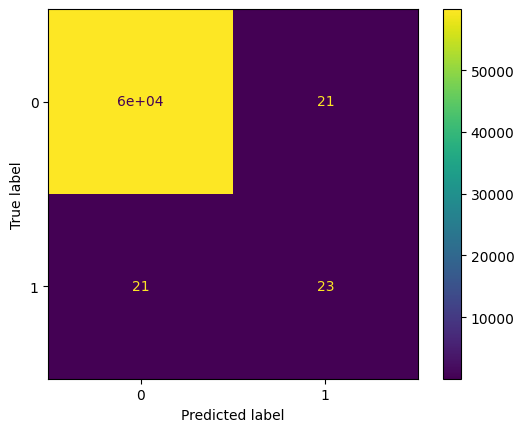

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(dt_clf, X_test, y_test)


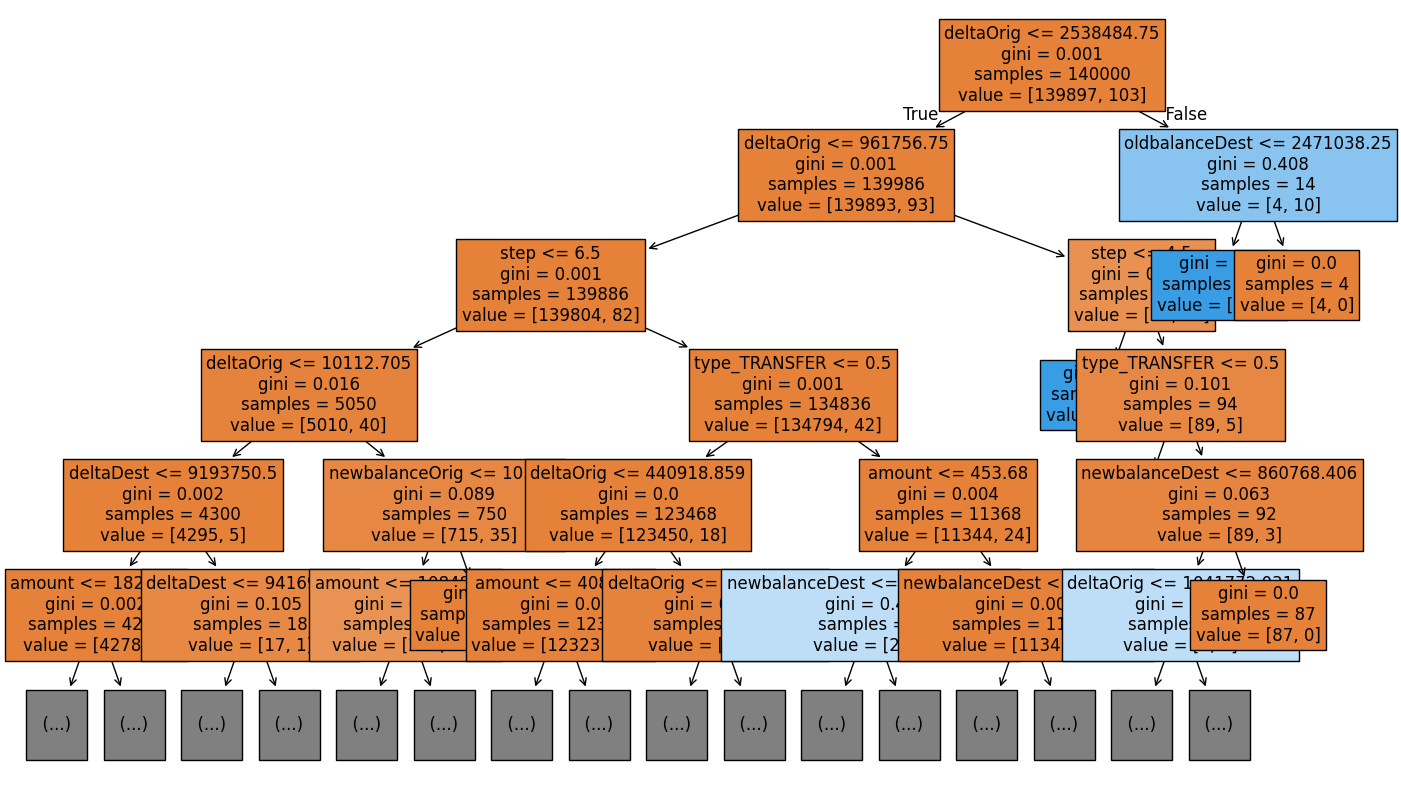

In [36]:
from sklearn.tree import plot_tree

fig = plt.figure(figsize=(17, 10))
_ = plot_tree(dt_clf, max_depth=5, feature_names=list(X_train.columns), filled=True, fontsize=12)


In [37]:
fi = pd.DataFrame({'features': X_train.columns, 'importance': dt_clf.feature_importances_}).sort_values(by=['importance'], ascending=False)
fi

,features,importance
6,deltaOrig,0.242983
1,amount,0.207889
10,type_PAYMENT,0.102984
7,deltaDest,0.095552
5,newbalanceDest,0.086261
4,oldbalanceDest,0.085305
0,step,0.065578
2,oldbalanceOrg,0.042726
3,newbalanceOrig,0.042172
11,type_TRANSFER,0.018221


# Exercise 1.10

deltaOrig is important

<Axes: xlabel='importance', ylabel='features'>

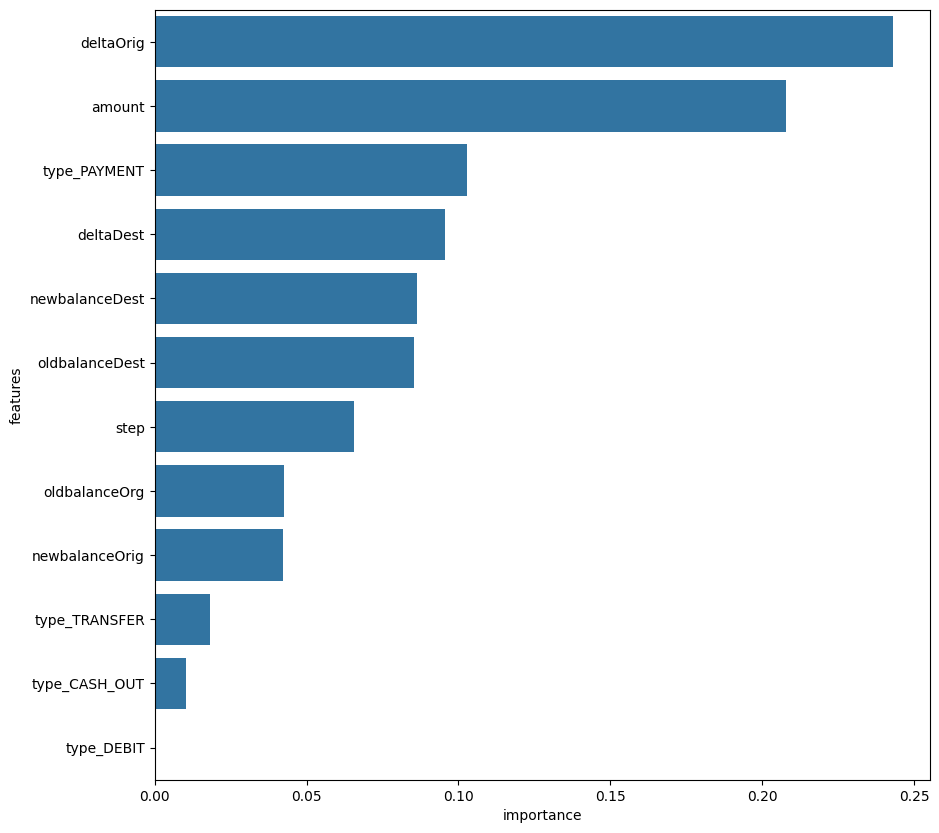

In [38]:
plt.figure(figsize=(10, 10))
sns.barplot(x="importance", y="features", data=fi)
